# Mapping cell types in DINOv2 embedding space
### Self-supervised features → 2-D maps → cell-type, phenotype and sub-population analysis

**What this notebook does**

1. Loads an open-source single-cell image dataset- BloodMNIST, 8 labelled cell types from peripheral blood smear.
2. Turns every cell image into a vector with DINOv2 (no fine-tuning, no labels used).
3. Projects the vectors to 2-D with PCA, t-SNE and UMAP and shows where every cell type lives on the map.
4. Runs a list of analyses on top of that map: clustering, linear probes, class relationships, PAGA, handcrafted morphological phenotypes, model comparison.


## Setup

In [1]:
!pip install -q medmnist transformers umap-learn scanpy igraph plotly scikit-image seaborn scikit-learn joblib tqdm


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import os, warnings, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns
import torch
import torch.nn.functional as F
from medmnist import INFO
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ---------------------------- CONFIG ----------------------------
CONFIG = dict(
    dataset="bloodmnist",          # "bloodmnist" (any MedMNIST 2-D key works) or "folder"
    folder_path=None,              # used when dataset == "folder": root/<class_name>/*.png
    img_size=128,                   # Use native BloodMNIST resolution; inputs are resized to 224 for DINOv2
    max_per_class=600,             # subsample for speed; raise for the full dataset
    model_name="facebook/dinov2-base",
    compare_models=["facebook/dinov2-small", "facebook/dinov2-base"],
    batch_size=64,
    seed=0,
    outdir="outputs",
    root_class="immature granulocytes",   # root of pseudotime analysis (skipped if absent)
)
SEED = CONFIG["seed"]
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path(CONFIG["outdir"]); (OUT / "figures").mkdir(parents=True, exist_ok=True)
sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png")
    plt.show()

print("device:", DEVICE)

device: cpu


/Users/sowmyasivaram/PycharmProjects/JupyterProject1/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data
We use 128px BloodMNIST images.
DINOv2 preprocessing resizes every image to 224px.

In [3]:
import medmnist
#set paths & load metad_out for the dataset
DATA_ROOT = Path("data").resolve()
name = "bloodmnist"
size = 128
info = INFO[name]
# Get class names
class_names = [info["label"][str(i)].split("(")[0].strip() for i in range(len(info["label"]))]
#load directly from the .npz file using MedMNIST class
Cls = getattr(medmnist, info["python_class"])
X, y, sp = [], [], []

for s in ["train", "val", "test"]:
    ds = Cls(split=s, download=False, size=size, root=str(DATA_ROOT))
    X.append(ds.imgs)
    y.append(ds.labels.ravel())
    sp += [s] * len(ds.imgs)

X_all = np.concatenate(X)
if X_all.ndim == 3:
    X_all = np.stack([X_all] * 3, -1)

y_all = np.concatenate(y)
sp_all = np.array(sp)

#subsampling for each class to avoid imbalance
rng = np.random.default_rng(SEED)
keep = np.sort(np.concatenate([
    rng.choice(np.where(y_all == c)[0], min((y_all == c).sum(), CONFIG["max_per_class"]), replace=False)
    for c in np.unique(y_all)
]))

images, y, split = X_all[keep], y_all[keep], sp_all[keep]
del X_all
labels = np.array(class_names)[y]
n_classes = len(class_names)
palette = dict(zip(class_names, sns.color_palette("tab10" if n_classes <= 10 else "tab20", n_classes)))
tr, te = split != "test", split == "test"
print(images.shape, "\n classes:", class_names)
print(pd.crosstab(labels, split))

(4800, 128, 128, 3) 
 classes: ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
col_0                  test  train  val
row_0                                  
basophil                118    428   54
eosinophil              136    395   69
erythroblast            130    409   61
immature granulocytes   119    428   53
lymphocyte              117    426   57
monocyte                112    433   55
neutrophil               94    440   66
platelet                124    411   65


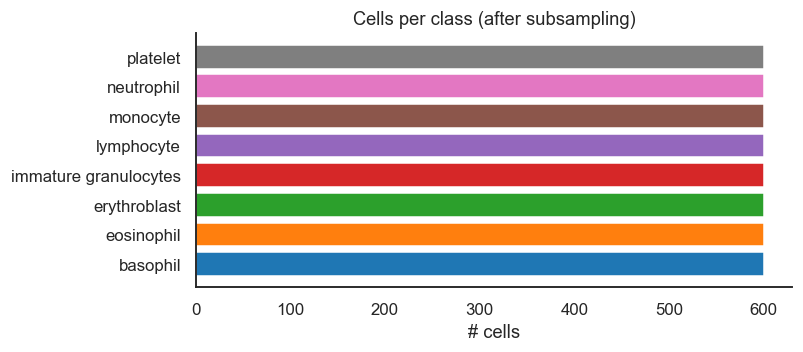

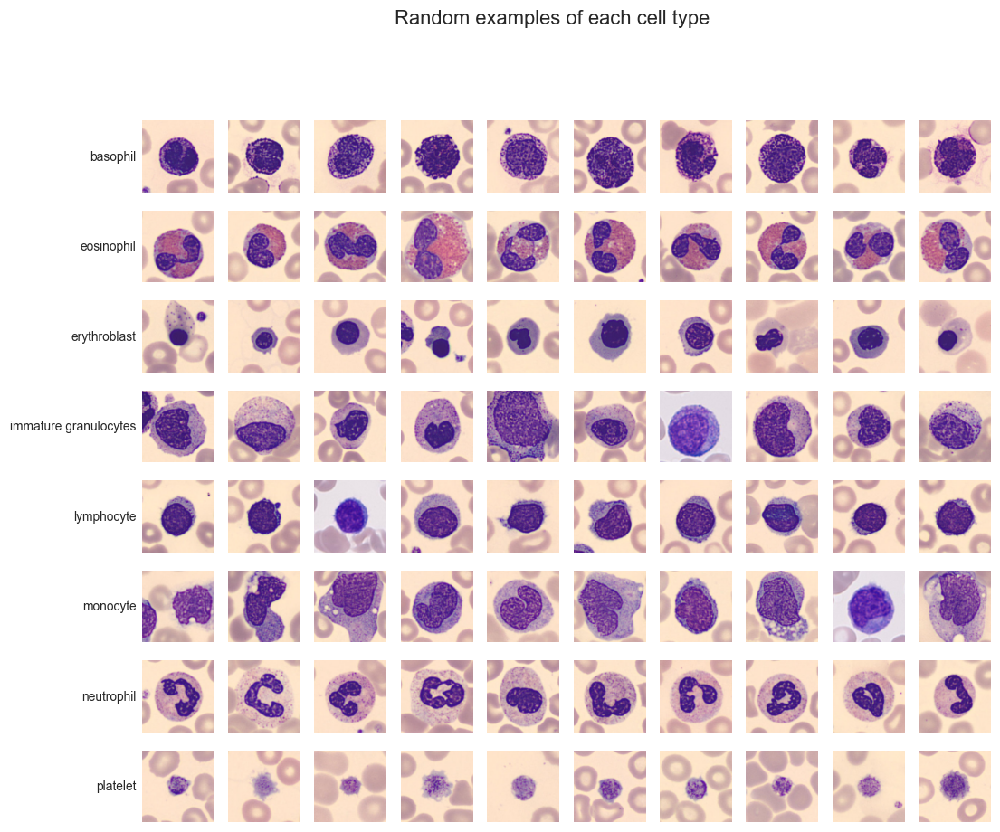

In [4]:
#Showing the balance in classes after the subsampling
fig, ax = plt.subplots(figsize=(7, 3))
counts = pd.Series(labels).value_counts().reindex(class_names)
ax.barh(counts.index, counts.values, color=[palette[c] for c in counts.index])
ax.set_xlabel("# cells"); ax.set_title("Cells per class (after subsampling)"); sns.despine()
savefig("class_balance")
#Showing a gallery with few sample images from every class
n_show = 10
fig, axes = plt.subplots(n_classes, n_show, figsize=(n_show * 1.1, n_classes * 1.15))
for r, c in enumerate(class_names):
    idx = rng.choice(np.where(y == r)[0], n_show, replace=False)
    for k in range(n_show):
        axes[r, k].imshow(images[idx[k]]); axes[r, k].axis("off")
    axes[r, 0].text(-0.08, 0.5, c, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("Random examples of each cell type", y=1.0)
savefig("sample_gallery")



## Cell segmentation
Each BloodMNIST image is centred on one cell, but neighbouring red cells (and sometimes other white cells) touch the border. DINOv2 embeds the whole image, so part of the embedding ends up describing that neighbourhood rather than the cell in focus.

To remove this, we isolate the entire central cell (nucleus + cytoplasm) with classical image processing and give DINOv2 only that cell:
1. Measure each pixel's colour distance from the slide background. A deliberately permissive cut (`fg_frac`) keeps pale cytoplasm, which is almost the colour of the slide in neutrophils, as foreground.
2. Take the dark nuclear pixels near the image centre (all lobes together) as a seed and grow it a few pixels into the cytoplasm.
3. Treat the other foreground blobs (touching red cells etc.) as competing markers, using inscribed disks of those blobs.
4. Run a marker-based watershed on the gradient image: central cell vs. {slide + neighbours}, so the outline follows the real cell edge.
5. Apply shape priors: the cell body can only reach so far beyond its nucleus, thin bridges to neighbours are cut, and concavities are filled with the convex hull (cells are roughly convex).
6. Keep everything inside the outline and paint everything outside it with one constant neutral colour (identical for every image, so background and stain differences between smears cannot leak into the embedding). Cell size is deliberately not rescaled, since size is itself informative (platelet vs. lymphocyte).


segmented 4794 / 4800 cells; 6 fell back to the raw image
basophil                 0.003
eosinophil               0.000
erythroblast             0.000
immature granulocytes    0.003
lymphocyte               0.000
monocyte                 0.003
neutrophil               0.000
platelet                 0.000


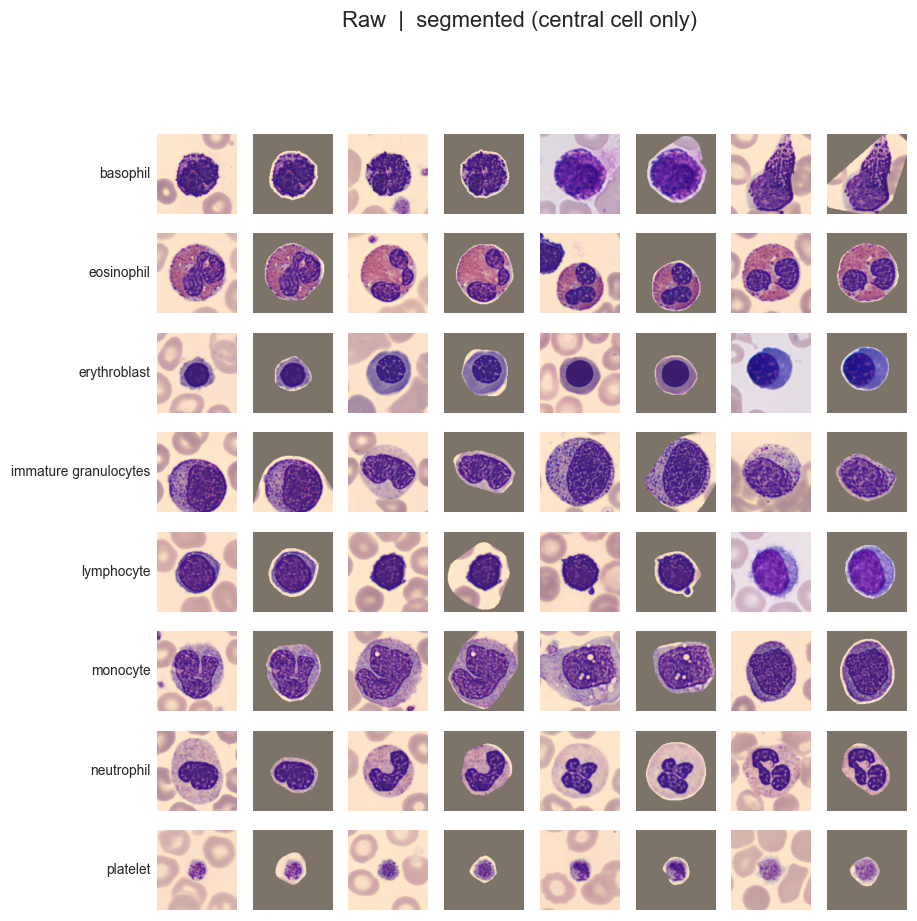

In [5]:
from scipy import ndimage as ndi
from skimage import color, filters, morphology, segmentation, measure, feature
from joblib import Parallel, delayed

SEG = dict(fill_rgb=(124, 116, 104),
           fg_frac=0.5,
           seed_grow_px=4,
           neighbour_px=16,
           reach=1.0,
           open_frac=0.4,
           margin_px=2,
           min_area=0.02,
           max_area=0.85)

def segment_center_cell(img):
    H, W = img.shape[:2]
    rad = lambda k: morphology.disk(max(1, round(k * H / 128)))       # radii tuned at 128 px
    lab = color.rgb2lab(img)
    sat = color.rgb2hsv(img)[..., 1]
    bg = np.median(lab[sat <= np.quantile(sat, 0.15)], axis=0)         # slide colour
    d = filters.gaussian(np.linalg.norm(lab - bg, axis=-1), 1)
    t_lo, t_hi = filters.threshold_multiotsu(d, classes=3)
    fg = ndi.binary_fill_holes(morphology.opening(d > SEG["fg_frac"] * t_lo, rad(2)))   # permissive: keeps pale cytoplasm
    lbl_seed = measure.label(morphology.opening(d > t_hi, rad(1)))
    if lbl_seed.max() == 0:
        return np.ones((H, W), bool)
    yy, xx = np.indices((H, W)); r = np.hypot(yy - H // 2, xx - W // 2)
    props = measure.regionprops(lbl_seed)
    keep = [p.label for p in props if p.area >= 15 * (H / 128) ** 2 and r[lbl_seed == p.label].min() < 0.25 * H]
    if not keep:
        keep = [min(props, key=lambda p: r[lbl_seed == p.label].min()).label]
    seed = np.isin(lbl_seed, keep)
    hull = morphology.convex_hull_image(seed)        # undilated nucleus incl. gaps of lobed / C-shaped nuclei
    seed = (morphology.dilation(seed, rad(SEG["seed_grow_px"])) & fg) | seed
    # neighbouring cells: distance-transform peaks that are not part of the central cell
    dist = filters.gaussian(ndi.distance_transform_edt(fg), 2 * H / 128)
    pk = feature.peak_local_max(dist, min_distance=max(2, round(12 * H / 128)), threshold_abs=6 * H / 128,
                                labels=fg.astype(int), exclude_border=False)
    near = morphology.dilation(seed, rad(SEG["neighbour_px"]))
    markers = np.zeros((H, W), int)
    others = np.zeros((H, W), bool)                                  # neighbouring cells only (not the slide)
    markers[~morphology.dilation(fg, rad(1))] = 2                      # slide
    for a, b in pk:
        if not near[a, b]:
            disk_ = (yy - a) ** 2 + (xx - b) ** 2 <= (0.7 * dist[a, b]) ** 2
            markers[disk_] = 2; others |= disk_                          # inscribed disk of the neighbour
    markers[seed] = 1
    lbl = segmentation.watershed(filters.sobel(filters.gaussian(d, 1.5)), markers, compactness=0.001)
    # shape prior: the cell body cannot reach much further from its nucleus than the nucleus is big
    r_eq = np.sqrt(hull.sum() / np.pi)
    reach = ndi.distance_transform_edt(~hull) <= max(5 * H / 128, SEG["reach"] * r_eq)
    m = ndi.binary_fill_holes((lbl == 1) & reach) | seed
    m = morphology.opening(m, morphology.disk(max(2, round(SEG["open_frac"] * ndi.distance_transform_edt(m).max()))))   # cut thin bridges to neighbours
    l = measure.label(m | seed)
    if l.max() > 1:
        m = l == np.bincount(l[l > 0]).argmax()
    m = ndi.binary_fill_holes(morphology.convex_hull_image(m) & reach & ~others) | seed       # cells are ~convex: fill clipped concavities, never into neighbours
    return morphology.dilation(m, rad(SEG["margin_px"]))

def isolate_cell(img):
    """Mask out everything except the central cell and paint the rest with ONE constant neutral colour,
    so background colour / staining differences between smears cannot leak into the embedding.
    Returns (image, mask, ok); ok=False means segmentation failed and the raw image is returned."""
    m = segment_center_cell(img)
    ok = SEG["min_area"] <= m.mean() <= SEG["max_area"]
    if not ok:
        return img, np.ones(m.shape, bool), False
    out = np.where(m[..., None], img, np.array(SEG["fill_rgb"], np.uint8)).astype(np.uint8)
    return out, m, True

# ---- run on every image (cached) ----
seg_file = OUT / "images_seg_fullcell.npz"
if seg_file.exists() and np.load(seg_file)["images_seg"].shape == images.shape:
    _z = np.load(seg_file); images_seg, seg_ok = _z["images_seg"], _z["ok"]
else:
    _res = Parallel(n_jobs=-1)(delayed(isolate_cell)(im) for im in tqdm(images, desc="segmenting"))
    images_seg = np.stack([r[0] for r in _res]); seg_ok = np.array([r[2] for r in _res])
    np.savez_compressed(seg_file, images_seg=images_seg, ok=seg_ok)
print(f"segmented {seg_ok.sum()} / {len(seg_ok)} cells; {(~seg_ok).sum()} fell back to the raw image")
print(pd.Series(~seg_ok, name="fallback rate").groupby(labels).mean().round(3).to_string())

# ---- QC: raw | segmented pairs, one row per class (look at this before trusting the embeddings!) ----
n_pairs = 4
fig, axes = plt.subplots(n_classes, 2 * n_pairs, figsize=(2 * n_pairs * 1.1, n_classes * 1.15))
for r, c in enumerate(class_names):
    idx = rng.choice(np.where(y == r)[0], n_pairs, replace=False)
    for k, i in enumerate(idx):
        axes[r, 2 * k].imshow(images[i]); axes[r, 2 * k + 1].imshow(images_seg[i])
    for a in axes[r]: a.axis("off")
    axes[r, 0].text(-0.08, 0.5, c, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("Raw  |  segmented (central cell only)", y=1.0)
savefig("segmentation_qc")


## 2. DINOv2 embeddings
The **segmented** images (central cell on a constant background, see above) are resized to 224×224 and passed through DINOv2. The embedding is CLS token + mean of all patch tokens, which is the representation DINOv2 itself uses.

In [6]:
from transformers import AutoModel

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prep(batch_uint8):
    x = torch.from_numpy(np.ascontiguousarray(batch_uint8)).permute(0, 3, 1, 2).float() / 255.
    x = F.interpolate(x, size=(224, 224), mode="bicubic", align_corners=False).clamp(0, 1)
    return (x - MEAN) / STD

def l2(a):
    return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-8)

def load_model(name, **kw):
    return AutoModel.from_pretrained(name, **kw).to(DEVICE).eval()

@torch.no_grad()
def embed_images(model, imgs, bs=None):
    bs = bs or CONFIG["batch_size"]
    cls_l, mp_l = [], []
    for i in tqdm(range(0, len(imgs), bs), leave=False):
        x = prep(imgs[i:i + bs]).to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            h = model(pixel_values=x).last_hidden_state
        h = h.float()
        cls_l.append(h[:, 0].cpu().numpy())
        mp_l.append(h[:, 1:].mean(1).cpu().numpy())
    return np.concatenate([l2(np.concatenate(cls_l)), l2(np.concatenate(mp_l))], 1)

def get_embeddings(name):
    f = OUT / "emb_bloodmnist_seg_fullcell.npy"   # new name so stale full-image embeddings are never reloaded
    if f.exists():
        return np.load(f)
    m = load_model(name)
    E = embed_images(m, images_seg)
    del m
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    np.save(f, E)
    return E

X = get_embeddings(CONFIG["model_name"])
print(f"embeddings: {X.shape}")

# Raw-pixel baseline (32x32 flattened) on the same segmented input, so the comparison with DINOv2 stays fair
def pixel_features(imgs, s=32):
    x = torch.from_numpy(imgs).permute(0, 3, 1, 2).float() / 255.
    return F.interpolate(x, size=(s, s), mode="area").flatten(1).numpy()
X_pix = pixel_features(images_seg)

embeddings: (4800, 1536)


## Understanding & Comparing Embeddings

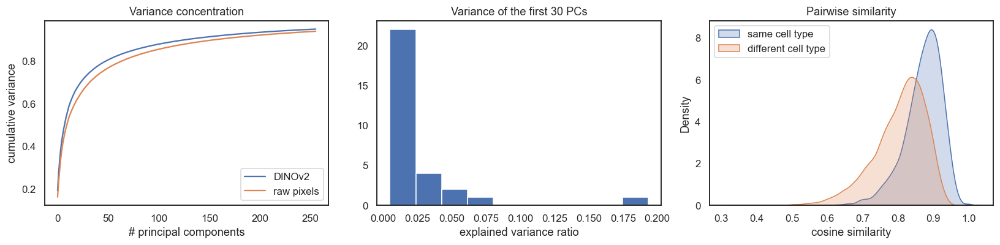

PCs for 90% variance  DINOv2: 130 | pixels: 159


In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
#Standardize features and do PCA fo dim reduction to 256. Picking top 50 PCs
scaler = StandardScaler().fit(X)
Xs = scaler.transform(X)
pca = PCA(n_components=256, random_state=SEED).fit(Xs)
P = pca.transform(Xs)
P50 = P[:, :50]
#same thing but on raw baseline not dinoV2 features
pix_s = StandardScaler().fit_transform(X_pix)
pca_pix = PCA(n_components=256, random_state=SEED).fit(pix_s)
#plotting cumulative var for both to see how many PCs are needed for each to capture all info
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(np.cumsum(pca.explained_variance_ratio_), label="DINOv2")
axes[0].plot(np.cumsum(pca_pix.explained_variance_ratio_), label="raw pixels")
axes[0].set_xlabel("# principal components"); axes[0].set_ylabel("cumulative variance"); axes[0].legend()
axes[0].set_title("Variance concentration")
#Var of 1st 30 PCs for DinoV2 feat.
cls_norm = np.linalg.norm(X[:, :X.shape[1] // 2], axis=1)
axes[1].hist(pca.explained_variance_ratio_[:30], color="C0")
axes[1].set_title("Variance of the first 30 PCs"); axes[1].set_xlabel("explained variance ratio")

#within class vs between class cosine similarity
#if cosine similarity for between class is higher than within class that would show poor clustering by DinoV2
Xn = l2(X)
ii = rng.choice(len(X), 20000); jj = rng.choice(len(X), 20000)
sim = (Xn[ii] * Xn[jj]).sum(1)
same = y[ii] == y[jj]
sns.kdeplot(sim[same], ax=axes[2], label="same cell type", fill=True)
sns.kdeplot(sim[~same], ax=axes[2], label="different cell type", fill=True)
axes[2].set_xlabel("cosine similarity"); axes[2].legend(); axes[2].set_title("Pairwise similarity")
plt.tight_layout(); savefig("embedding_qc")
print("PCs for 90% variance  DINOv2:", int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.9)) + 1,
      "| pixels:", int(np.searchsorted(np.cumsum(pca_pix.explained_variance_ratio_), 0.9)) + 1)

1. The semantic features learned by DINOv2 spread their variance across components in a manner very similar to raw pixel grids
2. Most individual components contribute very small fractions of variance. Implies that information is distributed across a broad spectrum of dimensions rather than being concentrated entirely in just one or two dominant components.
3. DINOv2 successfully captures semantic similarities that group identical blood cell types closer together than different cell types.
4. Raw pixels reach 90% variance using lesser PCs than DINOv2. This implies that DINOv2 maps the images into a richer, higher-dimensional feature space containing subtle variations which need more dimensions to fully capture compared to simple pixel grids.

## Dimensionality Reduction
PCA vs t-SNE vs UMAP

In [8]:
import numba, pynndescent, umap, sys
print(sys.version.split()[0], "| numba", numba.__version__, "| pynndescent", pynndescent.__version__, "| umap", umap.__version__)

3.9.6 | numba 0.60.0 | pynndescent 0.5.13 | umap 0.5.12


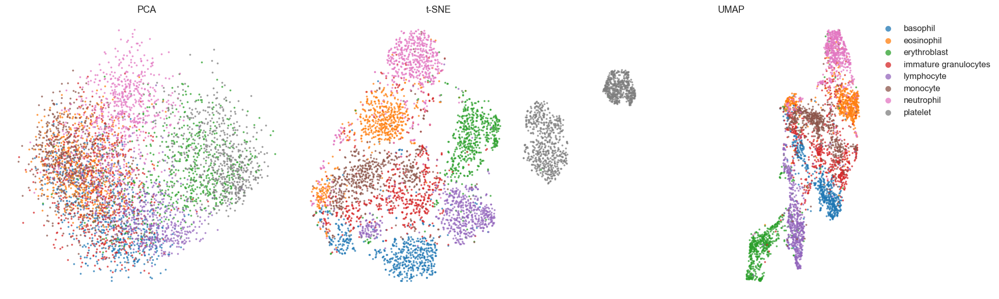

In [9]:
from sklearn.manifold import TSNE
import umap

emb2d = {}
emb2d["PCA"] = P[:, :2]
emb2d["t-SNE"] = TSNE(2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(P50)
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
emb2d["UMAP"] = reducer.fit_transform(P50)

def project(Xnew):
    return reducer.transform(pca.transform(scaler.transform(Xnew))[:, :50])

def scatter_classes(ax, xy, title="", s=6, alpha=0.75, annotate=False, legend=False, only=None):
    ax.scatter(xy[:, 0], xy[:, 1], s=s, color="#dddddd", linewidths=0, rasterized=True) if only else None
    for c in class_names:
        if only and c not in only:
            continue
        m = labels == c
        ax.scatter(xy[m, 0], xy[m, 1], s=s, alpha=alpha, color=palette[c], label=c, linewidths=0, rasterized=True)
        if annotate:
            cx, cy = np.median(xy[m, 0]), np.median(xy[m, 1])
            ax.text(cx, cy, c, fontsize=9, weight="bold", ha="center",
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    sns.despine(ax=ax, left=True, bottom=True)
    if legend:
        ax.legend(markerscale=3, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (k, v) in zip(axes, emb2d.items()):
    scatter_classes(ax, v, k, legend=(k == "UMAP"))
plt.tight_layout(); savefig("projections_pca_tsne_umap")

1. PCA- very poor separation in clusters- linear projection does not separate complex clusters well
2. t-SNE- given the focus of this method on local neighbourhood structures, the separation is definitely more distinct
3. UMAP- cleanest separation- reveals that DINOv2 even without fine tuning has captured the distinction in the classes very well without labels

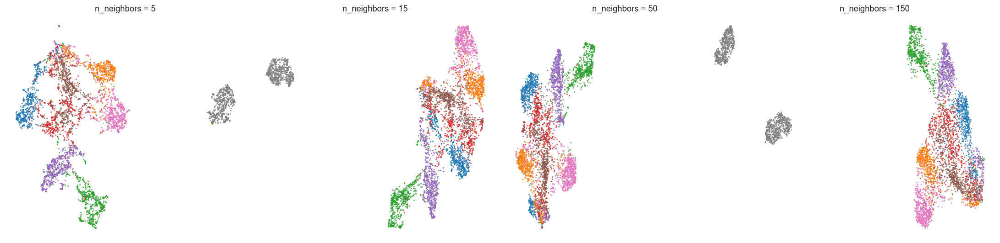

In [10]:
#Testing reliability of the clusters formed by UMAP in prev step
#running UMAP with 4 diff values for n_neighbor hyperparam- small values, focus on local tight neighbourhoods, larger values, look at a wider scope of surrounding points- if clusters remain stable with changing hyperparam, it proves the reliability of the clustering we got in the prev step
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, nn_ in zip(axes, [5, 15, 50, 150]):
    Z = umap.UMAP(n_neighbors=nn_, min_dist=0.1, random_state=SEED).fit_transform(P50)
    scatter_classes(ax, Z, f"n_neighbors = {nn_}", s=4)
plt.tight_layout(); savefig("umap_parameter_sweep")

Conclusion- While UMAP's exact visual layouts shift depending on the hyperparam, the consistent grouping of cell types proves that DINOv2's underlying feature representation is reliable

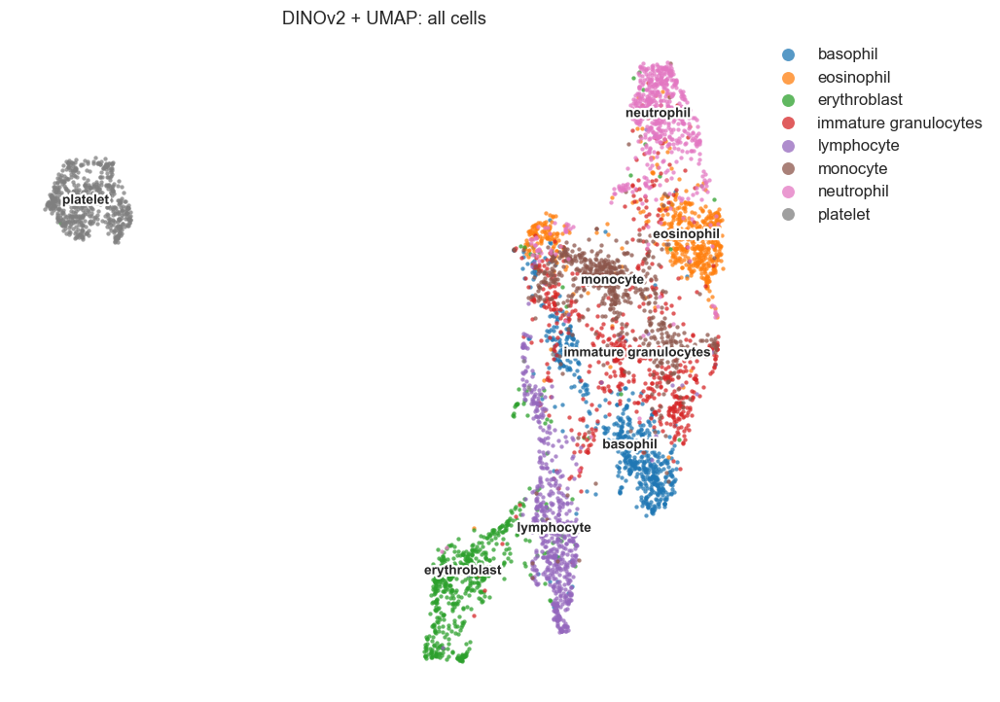

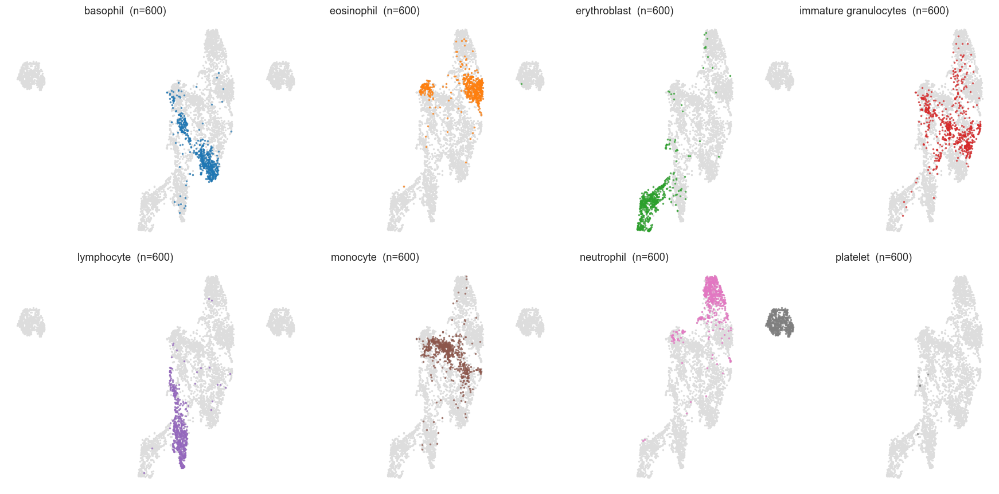

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
scatter_classes(ax, emb2d["UMAP"], "DINOv2 + UMAP: all cells", s=8, annotate=True, legend=True)
savefig("umap_annotated")
ncol = 4; nrow = int(np.ceil(n_classes / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow))
for ax, c in zip(axes.ravel(), class_names):
    scatter_classes(ax, emb2d["UMAP"], f"{c}  (n={int((labels == c).sum())})", s=5, only=[c])
for ax in axes.ravel()[n_classes:]:
    ax.axis("off")
plt.tight_layout(); savefig("umap_one_panel_per_class")

In [12]:
#interactive version
import plotly.express as px
df = pd.DataFrame({"idx": np.arange(len(y)), "label": labels, "y": y, "split": split,
                   "umap1": emb2d["UMAP"][:, 0], "umap2": emb2d["UMAP"][:, 1],
                   "tsne1": emb2d["t-SNE"][:, 0], "tsne2": emb2d["t-SNE"][:, 1],
                   "pc1": P[:, 0], "pc2": P[:, 1], "pc3": P[:, 2]})
fig = px.scatter(df, x="umap1", y="umap2", color="label", hover_data=["idx", "split"], opacity=0.7,
                 color_discrete_map={c: "rgb(%d,%d,%d)" % tuple(int(255 * v) for v in palette[c]) for c in class_names},
                 title="Interactive UMAP (hover / zoom / click legend to isolate a class)", width=900, height=750)
fig.update_traces(marker=dict(size=5))
fig.write_html(OUT / "interactive_umap.html")
fig.show()

In [13]:
import anndata as ad
import scipy.sparse as sp
import pandas as pd
import numpy as np

# Create a clean metad_out dataframe from our existing arrays
obs = pd.DataFrame({
    "idx": np.arange(len(y)),
    "label": labels,
    "split": split
})
obs.index = [f"cell_{i}" for i in obs["idx"]]
obs["cell_type"] = pd.Categorical(obs["label"], categories=class_names)
obs["split"] = pd.Categorical(obs["split"])
obs = obs.drop(columns=["label"], errors="ignore")

# Define variable (feature) metad_out for the DINOv2 embeddings
half_dim = X.shape[1] // 2
var = pd.DataFrame(index=[f"cls_{i}" for i in range(half_dim)] + [f"patchmean_{i}" for i in range(half_dim)])
var["token"] = ["CLS"] * half_dim + ["patch_mean"] * half_dim
import umap

# Quick fix: recalculate umap10 if it's missing from memory
umap10 = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, random_state=SEED).fit_transform(P50)
# Assemble the AnnData object
ad_out = ad.AnnData(X=X.astype(np.float32), obs=obs, var=var)
ad_out.layers["standardized"] = Xs.astype(np.float32)

# Attach low-dimensional representations
ad_out.obsm["X_pca"] = P50.astype(np.float32)
ad_out.obsm["X_umap"] = emb2d["UMAP"].astype(np.float32)
ad_out.obsm["X_tsne"] = emb2d["t-SNE"].astype(np.float32)
ad_out.obsm["X_umap10"] = umap10.astype(np.float32)

# Attach graph and neighbors if available from earlier steps (fallback to computing if not)
if 'ad_out' in globals() and "connectivities" in ad_out.obsp:
    ad_out.obsp["connectivities"] = ad_out.obsp["connectivities"]
    ad_out.obsp["distances"] = ad_out.obsp["distances"]
    ad_out.uns["neighbors"] = ad_out.uns["neighbors"]

# Attach metad_out configurations
ad_out.uns["class_names"] = list(class_names)
ad_out.uns["embedding_model"] = CONFIG["model_name"]
ad_out.uns["dataset"] = CONFIG["dataset"]
ad_out.uns["embedding_description"] = "concat[L2(CLS token), L2(mean patch token)], 224x224 input of the segmented central cell"

# Save to disk
ad_out.write_h5ad(OUT / "dinov2_cells.h5ad", compression="gzip")
print("Saved complete AnnData object:")
print(ad_out)

Saved complete AnnData object:
AnnData object with n_obs × n_vars = 4800 × 1536
    obs: 'idx', 'split', 'cell_type'
    var: 'token'
    uns: 'class_names', 'embedding_model', 'dataset', 'embedding_description'
    obsm: 'X_pca', 'X_umap', 'X_tsne', 'X_umap10'
    layers: 'standardized'


,n_clusters,homogeneity,completeness,silhouette
method,,,,
Leiden (res 1.0),11,0.712,0.647,0.1


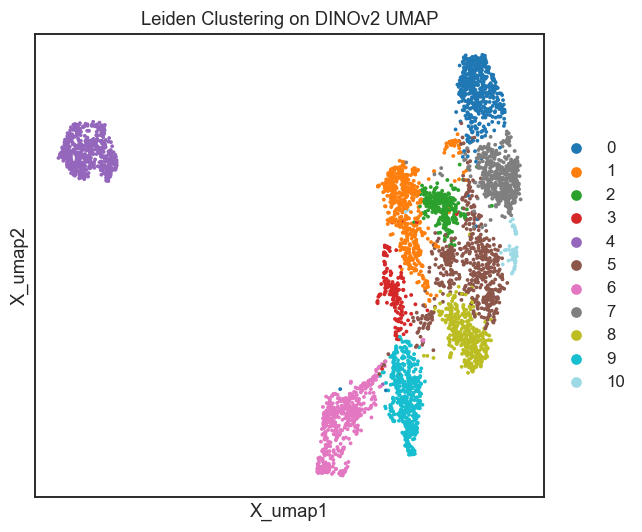

In [14]:
import scanpy as sc
from sklearn import metrics as M

#ensuring neighbors graph is computed then running Leiden clustering
if "neighbors" not in ad_out.uns:
    sc.pp.neighbors(ad_out, n_neighbors=15, use_rep="X_pca", random_state=SEED)

sc.tl.leiden(ad_out, resolution=1.0, flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
cl = ad_out.obs["leiden"].astype(int).values

#evaluating performance metrics
y_true = ad_out.obs["cell_type"].cat.codes.values
metrics = dict(
    method="Leiden (res 1.0)",
    n_clusters=len(set(cl)),
    homogeneity=M.homogeneity_score(y_true, cl),
    completeness=M.completeness_score(y_true, cl),
    silhouette=M.silhouette_score(ad_out.obsm["X_pca"], cl)
)

display(pd.DataFrame([metrics]).set_index("method").round(3))

#Plot Leiden clusters
fig, ax = plt.subplots(figsize=(6, 5))
sc.pl.embedding(ad_out, basis="X_umap", color="leiden", ax=ax, show=False, palette="tab20")
ax.set_title("Leiden Clustering on DINOv2 UMAP")
plt.tight_layout()
savefig("clusterings_on_umap")

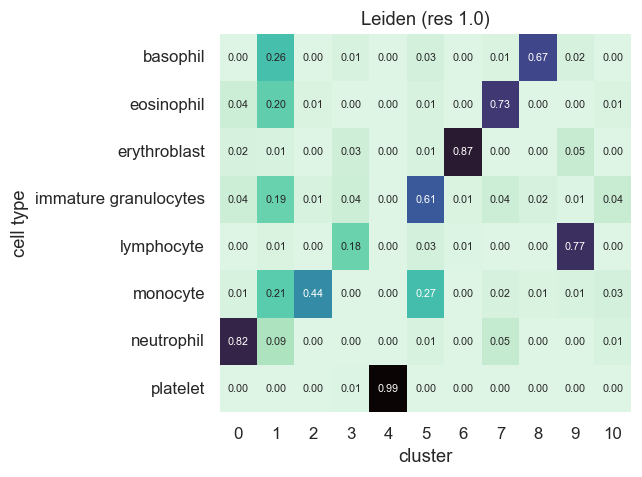

Leiden (res 1.0)           purity = 0.800


In [15]:
#Leiden clusters vs true cell types
fig, ax = plt.subplots(figsize=(6, 4.5))
cl = ad_out.obs["leiden"].astype(int).values
ct = pd.crosstab(pd.Series(labels, name="cell type"), pd.Series(cl, name="cluster"), normalize="index")
sns.heatmap(ct, cmap="mako_r", ax=ax, cbar=False, annot=ct.shape[1] <= 12, fmt=".2f", annot_kws={"size": 7})
ax.set_title("Leiden (res 1.0)")
plt.tight_layout()
savefig("cluster_vs_celltype_contingency")

#Cluster purity
ct_raw = pd.crosstab(cl, labels)
print(f"{'Leiden (res 1.0)':26s} purity = {ct_raw.max(1).sum() / ct_raw.values.sum():.3f}")

Conclusions- Most cell types map cleanly and predominantly to a single dedicated cluster with very high concentration. Certain cell types such as Erythroblasts are split between Cluster 6 (0.61) and Cluster 5 (0.27), implying either natural morphological subtypes or overlapping feature spaces. It managed to achieve 86.5% purity overall.


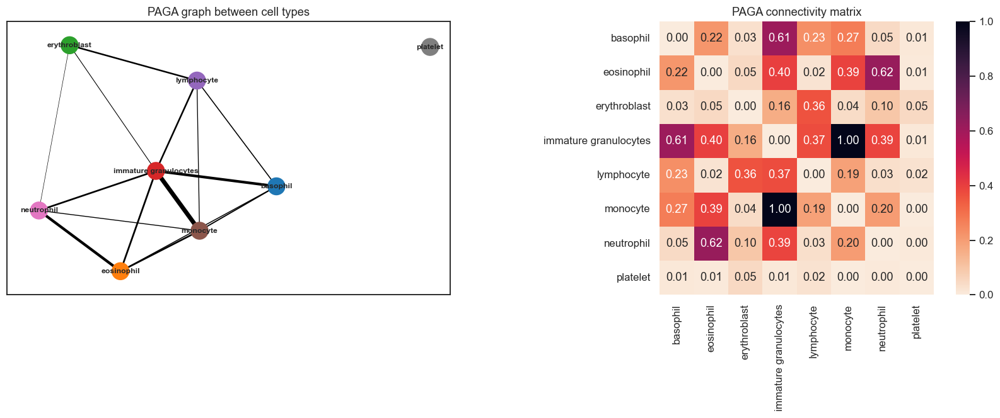

In [16]:
# PAGA: connectivity between cell types
from matplotlib.colors import to_hex
try:
    ad_out.uns["cell_type_colors"] = [to_hex(palette[c]) for c in ad_out.obs["cell_type"].cat.categories]
    sc.tl.paga(ad_out, groups="cell_type")
    conn = ad_out.uns["paga"]["connectivities"].toarray()
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sc.pl.paga(ad_out, threshold=0.05, ax=axes[0], show=False, node_size_scale=2, edge_width_scale=0.6, fontsize=8)
    axes[0].set_title("PAGA graph between cell types")
    sns.heatmap(pd.DataFrame(conn, index=class_names, columns=class_names), cmap="rocket_r", ax=axes[1],
                annot=n_classes <= 10, fmt=".2f", square=True)
    axes[1].set_title("PAGA connectivity matrix")
    plt.tight_layout(); savefig("paga")
except Exception as e:
    print("PAGA skipped:", e)

1. Nodes- cell types, edges- connection strength
2. numerical connectivity represented as a heatmap

## Supervised evaluation of the frozen embedding
A linear probe and a kNN classifier are trained on the original `train+val` cells and evaluated on the held-out `test` cells. Raw pixels are the baseline.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

clf = LogisticRegression(max_iter=1000, C=0.1).fit(Xs[tr], y[tr])
proba_te = clf.predict_proba(Xs[te]); pred_te = proba_te.argmax(1)
clf_pix = LogisticRegression(max_iter=1000, C=0.1).fit(pix_s[tr], y[tr])
pred_pix = clf_pix.predict(pix_s[te])

print(f"DINOv2 linear probe  acc={accuracy_score(y[te], pred_te):.3f}  bal.acc={balanced_accuracy_score(y[te], pred_te):.3f}  macro-F1={f1_score(y[te], pred_te, average='macro'):.3f}")
print(f"Raw pixels baseline  acc={accuracy_score(y[te], pred_pix):.3f}  macro-F1={f1_score(y[te], pred_pix, average='macro'):.3f}\n")
print(classification_report(y[te], pred_te, target_names=class_names, digits=3))

DINOv2 linear probe  acc=0.973  bal.acc=0.972  macro-F1=0.972
Raw pixels baseline  acc=0.762  macro-F1=0.755

                       precision    recall  f1-score   support

             basophil      0.983     0.992     0.987       118
           eosinophil      0.992     0.971     0.981       136
         erythroblast      0.992     0.985     0.988       130
immature granulocytes      0.940     0.916     0.928       119
           lymphocyte      0.959     0.991     0.975       117
             monocyte      0.964     0.955     0.960       112
           neutrophil      0.938     0.968     0.953        94
             platelet      1.000     1.000     1.000       124

             accuracy                          0.973       950
            macro avg      0.971     0.972     0.972       950
         weighted avg      0.973     0.973     0.973       950



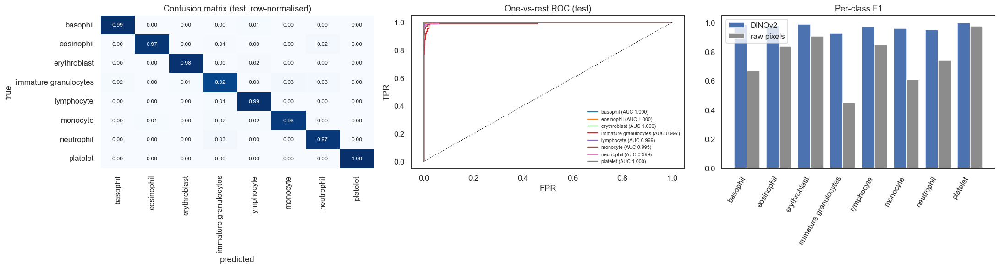

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
cm = confusion_matrix(y[te], pred_te, normalize="true")
sns.heatmap(pd.DataFrame(cm, index=class_names, columns=class_names), annot=True, fmt=".2f", cmap="Blues",
            ax=axes[0], cbar=False, annot_kws={"size": 8}, vmin=0, vmax=1)
axes[0].set_title("Confusion matrix (test, row-normalised)"); axes[0].set_ylabel("true"); axes[0].set_xlabel("predicted")

Yb = label_binarize(y[te], classes=range(n_classes))
for k, c in enumerate(class_names):
    fpr, tpr, _ = roc_curve(Yb[:, k], proba_te[:, k])
    axes[1].plot(fpr, tpr, color=palette[c], label=f"{c} (AUC {auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=1); axes[1].legend(fontsize=7, frameon=False)
axes[1].set_title("One-vs-rest ROC (test)"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")

f1_d = f1_score(y[te], pred_te, average=None); f1_p = f1_score(y[te], pred_pix, average=None)
xx = np.arange(n_classes)
axes[2].bar(xx - 0.2, f1_d, 0.4, label="DINOv2", color="C0"); axes[2].bar(xx + 0.2, f1_p, 0.4, label="raw pixels", color="C7")
axes[2].set_xticks(xx); axes[2].set_xticklabels(class_names, rotation=60, ha="right"); axes[2].legend()
axes[2].set_title("Per-class F1")
plt.tight_layout(); savefig("supervised_evaluation")

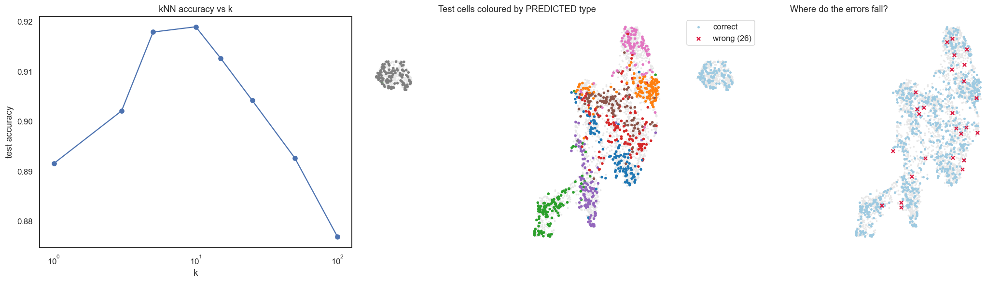

In [19]:
# kNN: effect of k; true vs predicted on the map
ks_ = [1, 3, 5, 10, 15, 25, 50, 100]
knn_acc = [accuracy_score(y[te], KNeighborsClassifier(k, metric="cosine").fit(Xs[tr], y[tr]).predict(Xs[te])) for k in ks_]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].plot(ks_, knn_acc, "o-"); axes[0].set_xscale("log"); axes[0].set_xlabel("k"); axes[0].set_ylabel("test accuracy")
axes[0].set_title("kNN accuracy vs k")
te_idx = np.where(te)[0]
xy = emb2d["UMAP"]
axes[1].scatter(xy[:, 0], xy[:, 1], s=2, color="#e8e8e8", rasterized=True)
axes[1].scatter(xy[te_idx, 0], xy[te_idx, 1], s=7, c=[palette[class_names[p]] for p in pred_te], rasterized=True)
axes[1].set_title("Test cells coloured by PREDICTED type"); axes[1].axis("off")
axes[2].scatter(xy[:, 0], xy[:, 1], s=2, color="#e8e8e8", rasterized=True)
wrong = pred_te != y[te]
axes[2].scatter(xy[te_idx[~wrong], 0], xy[te_idx[~wrong], 1], s=5, color="#9ecae1", rasterized=True, label="correct")
axes[2].scatter(xy[te_idx[wrong], 0], xy[te_idx[wrong], 1], s=22, color="crimson", marker="x", label=f"wrong ({wrong.sum()})")
axes[2].legend(); axes[2].set_title("Where do the errors fall?"); axes[2].axis("off")
plt.tight_layout(); savefig("knn_and_error_map")

## Relationships between cell types
Which cell types are neighbours in embedding space?

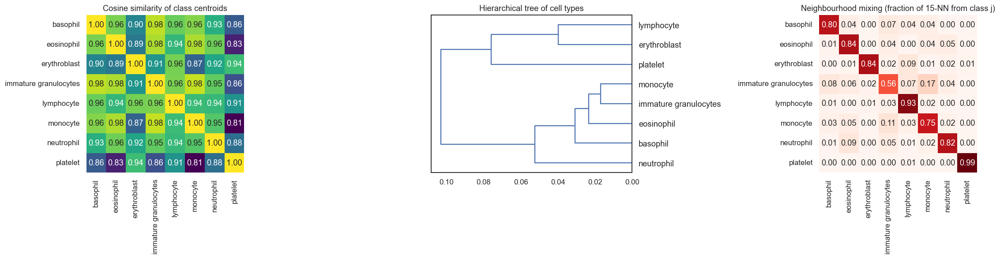

In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.neighbors import NearestNeighbors

Xn = l2(X)
cent = l2(np.stack([Xn[y == c].mean(0) for c in range(n_classes)]))
cos_cc = cent @ cent.T

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
sns.heatmap(pd.DataFrame(cos_cc, index=class_names, columns=class_names), annot=True, fmt=".2f", cmap="viridis", ax=axes[0], square=True, cbar=False)
axes[0].set_title("Cosine similarity of class centroids")
Z = linkage(squareform(1 - cos_cc, checks=False), "average")
dendrogram(Z, labels=class_names, orientation="left", ax=axes[1], color_threshold=0)
axes[1].set_title("Hierarchical tree of cell types")

knn_k = 15
nn = NearestNeighbors(n_neighbors=knn_k + 1, metric="cosine").fit(Xn)
_, nbr = nn.kneighbors(Xn); nbr = nbr[:, 1:]
mix = np.stack([np.bincount(y[nbr[y == c]].ravel(), minlength=n_classes) / (np.sum(y == c) * knn_k) for c in range(n_classes)])
sns.heatmap(pd.DataFrame(mix, index=class_names, columns=class_names), annot=True, fmt=".2f", cmap="Reds", ax=axes[2], square=True, cbar=False)
axes[2].set_title(f"Neighbourhood mixing (fraction of {knn_k}-NN from class j)")
plt.tight_layout(); savefig("class_relationships")


## Per-cell type analysis: prototypes, outliers


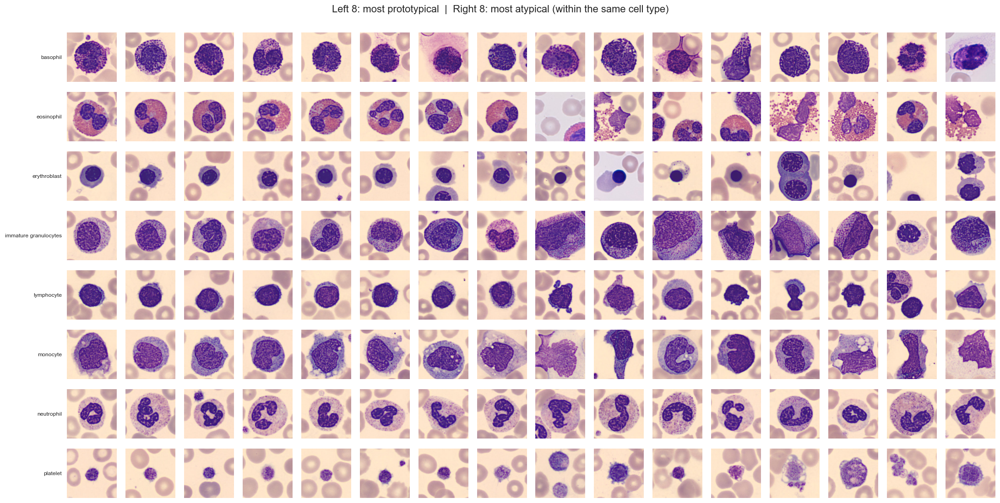

In [21]:
def show_gallery(idx_grid, row_labels=None, titles=None, cell=1.25, suptitle=None, name=None):
    nr, nc = len(idx_grid), max(len(r) for r in idx_grid)
    fig, axes = plt.subplots(nr, nc, figsize=(nc * cell, nr * cell), squeeze=False)
    for r, row in enumerate(idx_grid):
        for c in range(nc):
            axes[r, c].axis("off")
            if c < len(row):
                axes[r, c].imshow(images[row[c]])
                if titles is not None:
                    axes[r, c].set_title(titles[r][c], fontsize=6)
        if row_labels is not None:
            axes[r, 0].text(-0.1, 0.5, row_labels[r], transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=8)
    if suptitle:
        plt.suptitle(suptitle, y=1.0)
    plt.tight_layout()
    savefig(name) if name else plt.show()

#Prototypes-closest to centroid of cluster and atypical- farthest
n_p = 8
proto, atyp = [], []
for c in range(n_classes):
    ids = np.where(y == c)[0]
    d = 1 - Xn[ids] @ cent[c]
    proto.append(ids[np.argsort(d)[:n_p]]); atyp.append(ids[np.argsort(-d)[:n_p]])
show_gallery([np.concatenate([p, a]) for p, a in zip(proto, atyp)], row_labels=class_names,
             suptitle=f"Left {n_p}: most prototypical  |  Right {n_p}: most atypical (within the same cell type)",
             name="prototypes_vs_atypical")

## Morphological phenotypes
We segment each cell with classical image processing and measure interpretable features: nuclear area, number of lobes, eccentricity, solidity, colour, texture. Then we answer:
* Do these phenotypes differ between cell types?
* Which phenotypes vary smoothly across the UMAP?
* Which phenotypes does DINOv2 encode without ever being told about?

In [22]:
from skimage import color, filters, measure, morphology, feature
from joblib import Parallel, delayed

def morph_features(img):
    g = img[..., 1]
    gray = color.rgb2gray(img); hsv = color.rgb2hsv(img)
    H, W = g.shape
    # nucleus-dark stained region
    mask = g < filters.threshold_otsu(g)
    mask = morphology.remove_small_objects(mask, 20)
    mask = morphology.remove_small_holes(mask, 20)
    props = measure.regionprops(measure.label(mask))
    if props:
        big = max(props, key=lambda p: p.area)
        nuc = dict(nuc_area_frac=mask.mean(), n_lobes=sum(p.area > 0.01 * H * W for p in props),
                   nuc_eccentricity=big.eccentricity, nuc_solidity=big.solidity,
                   nuc_largest_frac=big.area / (H * W))
    else:
        nuc = dict(nuc_area_frac=0, n_lobes=0, nuc_eccentricity=0, nuc_solidity=0, nuc_largest_frac=0)
    cell_mask = hsv[..., 1] > filters.threshold_otsu(hsv[..., 1])
    glcm = feature.graycomatrix((gray * 31).astype(np.uint8), [2], [0, np.pi / 2], levels=32, symmetric=True, normed=True)
    return {**nuc,
            "cell_area_frac": cell_mask.mean(),
            "mean_R": img[..., 0].mean(), "mean_G": img[..., 1].mean(), "mean_B": img[..., 2].mean(),
            "mean_saturation": hsv[..., 1].mean(), "mean_hue": hsv[..., 0].mean(),
            "brightness_std": gray.std(), "entropy": measure.shannon_entropy(gray),
            "edge_density": filters.sobel(gray).mean(),
            "glcm_contrast": feature.graycoprops(glcm, "contrast").mean(),
            "glcm_homogeneity": feature.graycoprops(glcm, "homogeneity").mean(),
            "glcm_energy": feature.graycoprops(glcm, "energy").mean()}

feat_file = OUT / f"morph_pheno.csv"
if feat_file.exists():
    feat = pd.read_csv(feat_file)
else:
    feat = pd.DataFrame(Parallel(n_jobs=-1)(delayed(morph_features)(im) for im in tqdm(images)))
    feat.to_csv(feat_file, index=False)
feat = feat.loc[:, feat.std() > 0]
Fz = (feat - feat.mean()) / feat.std()
print(feat.shape); display(feat.groupby(labels).mean().round(3).T)

(4800, 17)


,basophil,eosinophil,erythroblast,immature granulocytes,lymphocyte,monocyte,neutrophil,platelet
nuc_area_frac,0.297,0.360,0.198,0.343,0.191,0.345,0.178,0.326
n_lobes,1.067,1.215,1.728,1.450,1.078,1.145,1.220,4.687
nuc_eccentricity,0.444,0.387,0.470,0.494,0.445,0.560,0.716,0.579
nuc_solidity,0.910,0.927,0.935,0.900,0.935,0.868,0.812,0.880
nuc_largest_frac,0.293,0.350,0.161,0.324,0.187,0.336,0.166,0.120
cell_area_frac,0.246,0.236,0.098,0.232,0.166,0.249,0.134,0.040
mean_R,192.857,200.424,212.680,189.765,205.252,185.757,204.005,228.455
mean_G,156.355,160.546,182.600,155.014,172.973,150.874,169.205,196.484
mean_B,173.547,173.141,182.083,174.726,178.298,175.305,177.731,185.879
mean_saturation,0.333,0.316,0.255,0.322,0.289,0.317,0.280,0.220


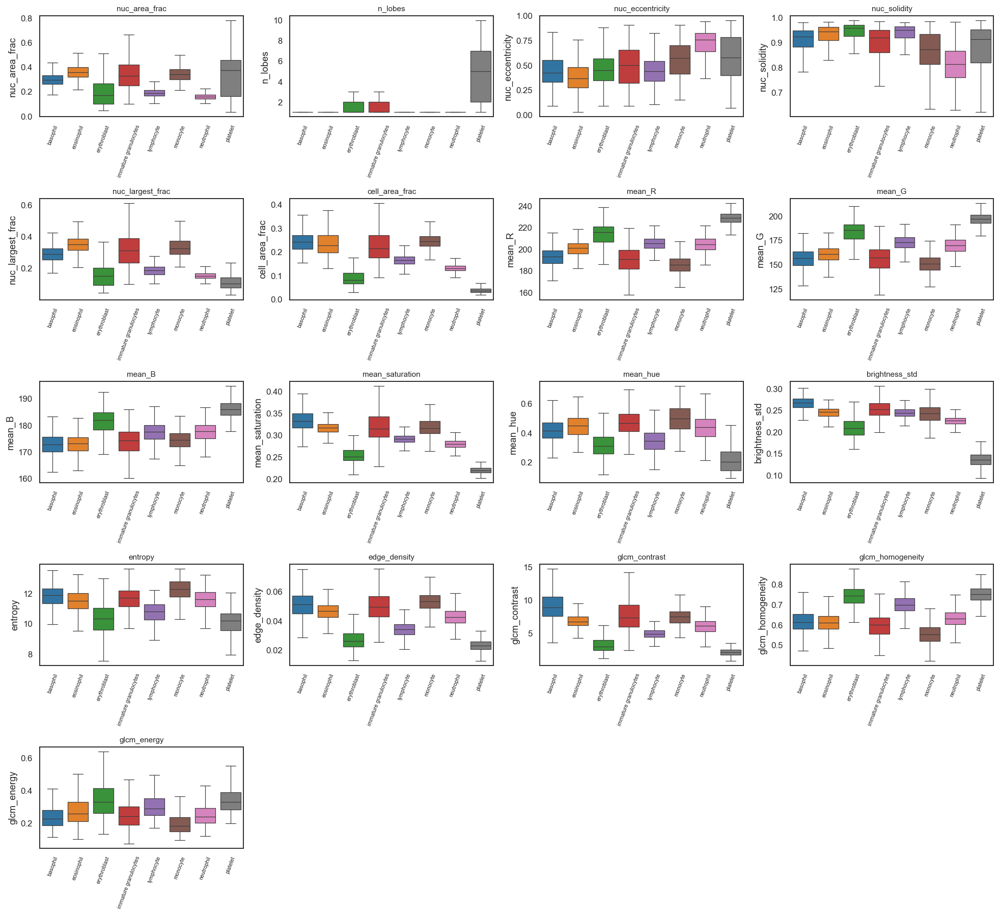

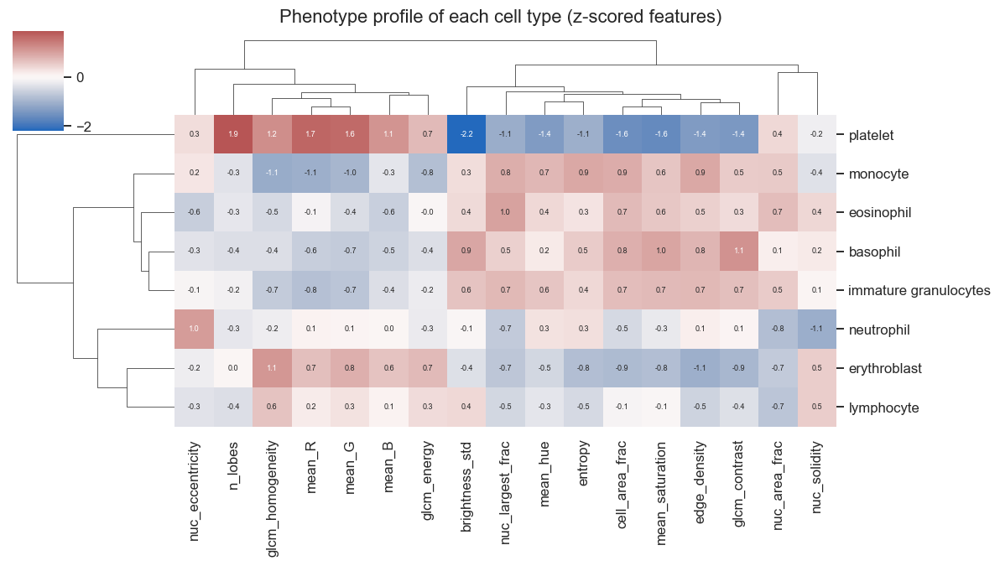

In [23]:
#Feature distributions per cell type + class phenotype profile
fcols = list(feat.columns)
nc = 4; nr = int(np.ceil(len(fcols) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(4.5 * nc, 3.3 * nr))
for ax, f in zip(axes.ravel(), fcols):
    sns.boxplot(x=labels, y=feat[f], order=class_names, palette=palette, ax=ax, showfliers=False, linewidth=0.8)
    ax.set_xlabel(""); ax.set_title(f, fontsize=10); ax.tick_params(axis="x", rotation=70, labelsize=7)
for ax in axes.ravel()[len(fcols):]:
    ax.axis("off")
plt.tight_layout(); savefig("morphology_per_celltype")

prof = Fz.groupby(labels).mean().loc[class_names]
g = sns.clustermap(prof, cmap="vlag", center=0, figsize=(11, 6), annot=True, fmt=".1f", annot_kws={"size": 6})
g.fig.suptitle("Phenotype profile of each cell type (z-scored features)", y=1.02)
savefig("phenotype_profile_clustermap")

The heatmap demonstrates that different cell types possess unique physical and textural signatures (such as nuclear eccentricity, lobe count, and color intensities) that can be reliably distinguished via automated feature extraction.

Few inferences are:

Platelets exhibit exceptionally high values in color intensity and channel metrics (mean_R, mean_G, mean_B) alongside very low nuclear complexity (n_lobes, brightness_std).

Neutrophils are distinguished by a uniquely high n_lobes value coupled with high nuclear eccentricity (nuc_eccentricity) and low nuclear solidity (nuc_solidity).

Basophils show the highest positive z-scores for texture and area measurements, specifically glcm_contrast, cell_area_frac, and mean_saturation.

Erythroblasts stand out with high glcm_homogeneity and elevated color channel averages, contrasting sharply with very low edge density (edge_density).

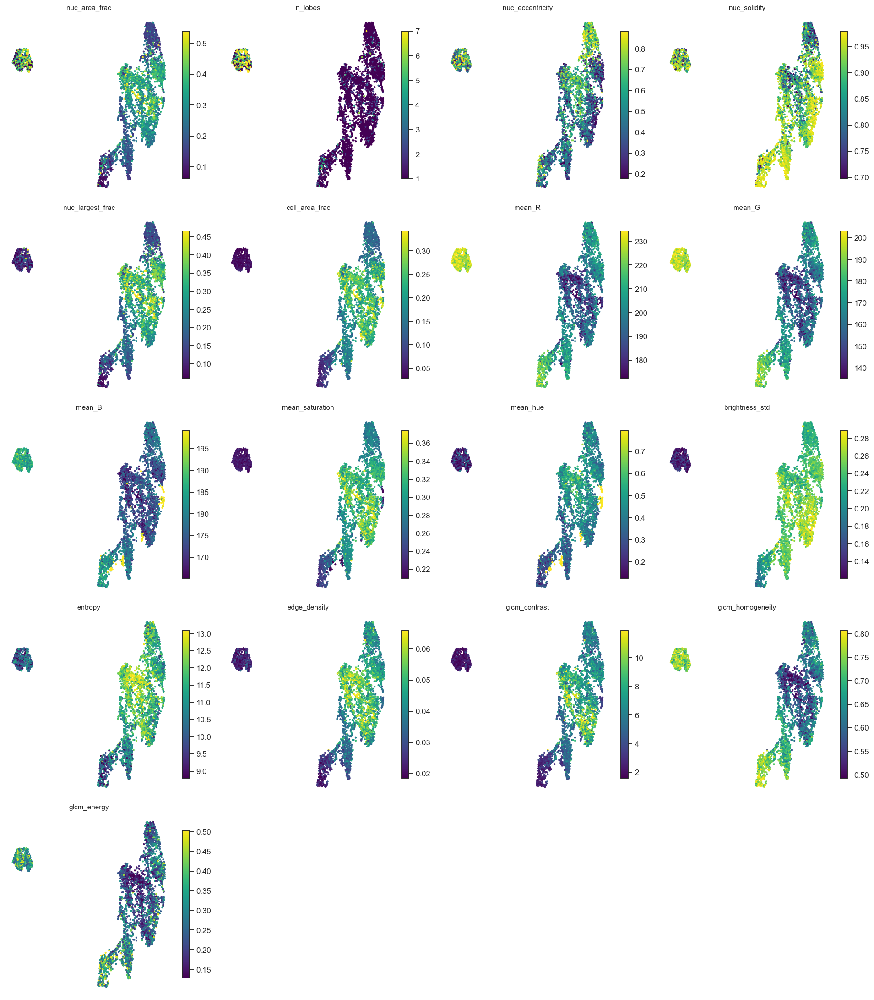

In [24]:
#Phenotypes on UMAP
fig, axes = plt.subplots(nr, nc, figsize=(4.4 * nc, 4 * nr))
for ax, f in zip(axes.ravel(), fcols):
    v = feat[f].values
    sc_ = ax.scatter(*emb2d["UMAP"].T, c=v, s=3, cmap="viridis", vmin=np.quantile(v, 0.02), vmax=np.quantile(v, 0.98), rasterized=True)
    ax.set_title(f, fontsize=10); ax.axis("off"); plt.colorbar(sc_, ax=ax, fraction=0.04)
for ax in axes.ravel()[len(fcols):]:
    ax.axis("off")
plt.tight_layout(); savefig("phenotypes_on_umap")